# Anti-Spoof Detector MobileNetV3 Small v1

Treina um classificador binario para prova de vida:

- `0 = live`
- `1 = spoof`

Use o kernel local `DeepTrustShield Training (.venv-training)` no VS Code.

In [18]:
from pathlib import Path
import json
import random
import time

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms

from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PROJECT_ROOT =', PROJECT_ROOT)
print('device =', device)
if torch.cuda.is_available():
    print('gpu =', torch.cuda.get_device_name(0))

PROJECT_ROOT = /home/wesleiferreira/Documentos/GitHub/DeepTrustShield
device = cuda
gpu = NVIDIA GeForce RTX 4050 Laptop GPU


## Configuracao

In [19]:
MANIFEST_PATH = PROJECT_ROOT / 'data/manifests/antispoof_manifest_folds.csv'
OUTPUT_DIR = PROJECT_ROOT / 'model/weights/antispoof_mobilenet_v1'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VAL_FOLD = 0
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 12
LR = 3e-4
WEIGHT_DECAY = 1e-4
THRESHOLD = 0.5

# Use 0 no VS Code se o notebook der erro de multiprocessing/BrokenPipe.
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available() and NUM_WORKERS > 0

BEST_CKPT_PATH = OUTPUT_DIR / 'antispoof_mobilenet_v1_best.pth'
LAST_CKPT_PATH = OUTPUT_DIR / 'antispoof_mobilenet_v1_last.pth'
ONNX_PATH = OUTPUT_DIR / 'antispoof_mobilenet_v1.onnx'
METADATA_PATH = OUTPUT_DIR / 'antispoof_mobilenet_v1_metadata.json'

print('manifest =', MANIFEST_PATH)
print('output =', OUTPUT_DIR)

manifest = /home/wesleiferreira/Documentos/GitHub/DeepTrustShield/data/manifests/antispoof_manifest_folds.csv
output = /home/wesleiferreira/Documentos/GitHub/DeepTrustShield/model/weights/antispoof_mobilenet_v1


## Carregar Manifesto

In [20]:
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f'Manifesto com folds nao encontrado: {MANIFEST_PATH}\n'
        'Gere com: worker/venv/bin/python scripts/build_antispoof_folds.py'
    )

df = pd.read_csv(MANIFEST_PATH)
required_cols = {'path', 'label', 'label_id', 'fold'}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f'Colunas ausentes no manifesto: {missing}')

df['path_abs'] = df['path'].apply(lambda p: str((PROJECT_ROOT / p).resolve()))
df['label_id'] = df['label_id'].astype(int)
df['fold'] = df['fold'].astype(int)

missing_files = df[~df['path_abs'].map(lambda p: Path(p).exists())]
if len(missing_files):
    raise FileNotFoundError(f'{len(missing_files)} arquivos do manifesto nao foram encontrados')

train_df = df[df['fold'] != VAL_FOLD].reset_index(drop=True)
val_df = df[df['fold'] == VAL_FOLD].reset_index(drop=True)

print('total:', len(df))
print('train:', len(train_df), train_df['label'].value_counts().to_dict())
print('val:', len(val_df), val_df['label'].value_counts().to_dict())
display(df.groupby(['fold', 'label']).size().unstack(fill_value=0))

total: 2000
train: 1622 {'spoof': 821, 'live': 801}
val: 378 {'live': 199, 'spoof': 179}


label,live,spoof
fold,,
0,199,179
1,200,178
2,200,233
3,201,175
4,200,235


## Dataset e Augmentations

In [21]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.18, contrast=0.18, saturation=0.12, hue=0.03)], p=0.7),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))], p=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class AntiSpoofDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(row['path_abs']).convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['label_id'], dtype=torch.float32)
        return image, label

def make_weighted_sampler(dataframe):
    counts = dataframe['label_id'].value_counts().to_dict()
    weights = dataframe['label_id'].map(lambda label: 1.0 / counts[int(label)]).to_numpy(dtype=np.float64)
    return WeightedRandomSampler(weights=weights, num_samples=len(weights), replacement=True)

train_dataset = AntiSpoofDataset(train_df, train_tfms)
val_dataset = AntiSpoofDataset(val_df, val_tfms)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=make_weighted_sampler(train_df),
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print('batches train:', len(train_loader), 'val:', len(val_loader))

batches train: 51 val: 12


## Modelo

In [22]:
class AntiSpoofMobileNetV3(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        self.backbone = models.mobilenet_v3_small(weights=weights)
        in_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier[-1] = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 1),
        )

    def forward(self, x):
        return self.backbone(x).squeeze(1)

model = AntiSpoofMobileNetV3().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'total_params={total_params:,} trainable={trainable_params:,}')

total_params=1,518,881 trainable=1,518,881


## Metricas

In [23]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    apcer = fn / max(tp + fn, 1)  # spoof aceito como live
    bpcer = fp / max(tn + fp, 1)  # live rejeitado como spoof
    acer = (apcer + bpcer) / 2

    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')

    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'auc': auc,
        'apcer': apcer,
        'bpcer': bpcer,
        'acer': acer,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

def find_best_threshold(y_true, y_prob):
    candidates = np.linspace(0.05, 0.95, 181)
    scored = [(thr, compute_metrics(y_true, y_prob, thr)) for thr in candidates]
    best_thr, best_metrics = min(scored, key=lambda item: (item[1]['acer'], item[1]['apcer'], item[1]['bpcer']))
    return float(best_thr), best_metrics

## Treino

In [24]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    y_true, y_prob = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += float(loss.item()) * images.size(0)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.detach().cpu().numpy().astype(int).tolist())

    return total_loss / len(loader.dataset), compute_metrics(y_true, y_prob, THRESHOLD)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    y_true, y_prob = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += float(loss.item()) * images.size(0)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.detach().cpu().numpy().astype(int).tolist())

    metrics = compute_metrics(y_true, y_prob, THRESHOLD)
    best_threshold, best_threshold_metrics = find_best_threshold(y_true, y_prob)
    return total_loss / len(loader.dataset), metrics, np.asarray(y_true), np.asarray(y_prob), best_threshold, best_threshold_metrics

history = []
best_acer = float('inf')
best_epoch = -1
started = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_metrics = train_one_epoch(model, train_loader)
    val_loss, val_metrics, y_val, p_val, best_thr, best_thr_metrics = evaluate(model, val_loader)
    scheduler.step(val_loss)

    row = {
        'epoch': epoch,
        'lr': optimizer.param_groups[0]['lr'],
        'train_loss': train_loss,
        'val_loss': val_loss,
        **{f'train_{k}': v for k, v in train_metrics.items()},
        **{f'val_{k}': v for k, v in val_metrics.items()},
        'val_best_threshold': best_thr,
        'val_best_acer': best_thr_metrics['acer'],
        'val_best_apcer': best_thr_metrics['apcer'],
        'val_best_bpcer': best_thr_metrics['bpcer'],
    }
    history.append(row)

    improved = val_metrics['acer'] < best_acer
    if improved:
        best_acer = val_metrics['acer']
        best_epoch = epoch
        torch.save({
            'model_state_dict': model.state_dict(),
            'config': {
                'model_name': 'mobilenet_v3_small',
                'task': 'face_anti_spoof',
                'image_size': IMAGE_SIZE,
                'imagenet_mean': IMAGENET_MEAN,
                'imagenet_std': IMAGENET_STD,
                'fold': VAL_FOLD,
                'threshold': THRESHOLD,
                'best_threshold': best_thr,
            },
            'epoch': epoch,
            'metrics': val_metrics,
            'best_threshold_metrics': best_thr_metrics,
        }, BEST_CKPT_PATH)

    torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch}, LAST_CKPT_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} "
        f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
        f"val_auc={val_metrics['auc']:.4f} val_f1={val_metrics['f1']:.4f} "
        f"APCER={val_metrics['apcer']:.4f} BPCER={val_metrics['bpcer']:.4f} ACER={val_metrics['acer']:.4f} "
        f"best_thr={best_thr:.2f} {'*' if improved else ''}"
    )

print(f'best_epoch={best_epoch} best_acer={best_acer:.4f} tempo_min={(time.time()-started)/60:.1f}')

Epoch 01/12 train_loss=0.2263 val_loss=0.0451 val_auc=0.9996 val_f1=0.9858 APCER=0.0279 BPCER=0.0000 ACER=0.0140 best_thr=0.28 *
Epoch 02/12 train_loss=0.0446 val_loss=0.0462 val_auc=0.9990 val_f1=0.9830 APCER=0.0335 BPCER=0.0000 ACER=0.0168 best_thr=0.36 
Epoch 03/12 train_loss=0.0195 val_loss=0.0221 val_auc=0.9999 val_f1=0.9915 APCER=0.0168 BPCER=0.0000 ACER=0.0084 best_thr=0.06 *
Epoch 04/12 train_loss=0.0148 val_loss=0.0212 val_auc=0.9996 val_f1=0.9944 APCER=0.0112 BPCER=0.0000 ACER=0.0056 best_thr=0.33 *
Epoch 05/12 train_loss=0.0241 val_loss=0.0183 val_auc=0.9999 val_f1=0.9915 APCER=0.0168 BPCER=0.0000 ACER=0.0084 best_thr=0.14 
Epoch 06/12 train_loss=0.0107 val_loss=0.0168 val_auc=0.9999 val_f1=0.9915 APCER=0.0168 BPCER=0.0000 ACER=0.0084 best_thr=0.28 


KeyboardInterrupt: 

## Curvas e Threshold

,epoch,train_loss,val_loss,val_auc,val_f1,val_apcer,val_bpcer,val_acer,val_best_threshold,val_best_acer
0,1,0.226190,0.044879,0.999635,0.985836,0.027933,0.000000,0.013966,0.260,0.005587
1,2,0.044514,0.047206,0.998933,0.982955,0.033520,0.000000,0.016760,0.405,0.016760
2,3,0.019404,0.022810,0.999860,0.991549,0.016760,0.000000,0.008380,0.105,0.005587
3,4,0.013942,0.022488,0.999832,0.991549,0.016760,0.000000,0.008380,0.125,0.005587
4,5,0.025956,0.040811,0.999326,0.988701,0.022346,0.000000,0.011173,0.150,0.008380
5,6,0.016723,0.010726,0.999972,0.994413,0.005587,0.005025,0.005306,0.205,0.002513
6,7,0.011262,0.019815,0.999888,0.991549,0.016760,0.000000,0.008380,0.085,0.005306
7,8,0.008579,0.022393,0.999663,0.991549,0.016760,0.000000,0.008380,0.370,0.008380
8,9,0.005132,0.011718,0.999972,0.994382,0.011173,0.000000,0.005587,0.050,0.002513
9,10,0.003631,0.028736,1.000000,0.988701,0.022346,0.000000,0.011173,0.050,0.005587


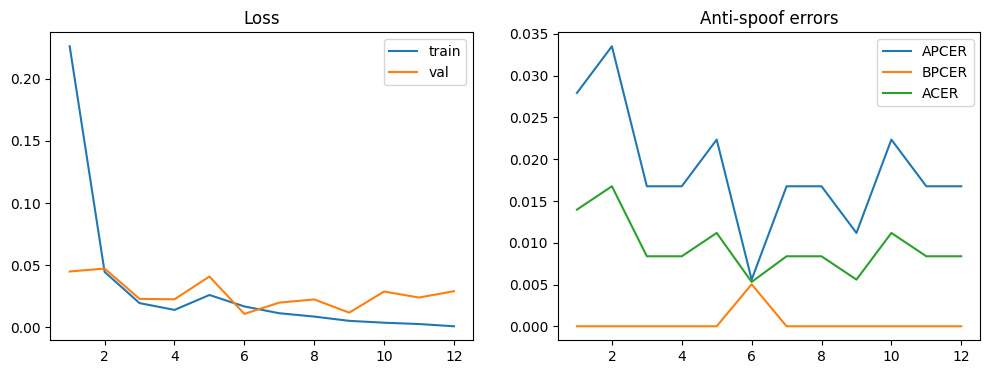

melhor threshold no fold: 0.20499999999999996


In [ ]:
hist = pd.DataFrame(history)
display(hist[['epoch', 'train_loss', 'val_loss', 'val_auc', 'val_f1', 'val_apcer', 'val_bpcer', 'val_acer', 'val_best_threshold', 'val_best_acer']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist['epoch'], hist['train_loss'], label='train')
axes[0].plot(hist['epoch'], hist['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].legend()

axes[1].plot(hist['epoch'], hist['val_apcer'], label='APCER')
axes[1].plot(hist['epoch'], hist['val_bpcer'], label='BPCER')
axes[1].plot(hist['epoch'], hist['val_acer'], label='ACER')
axes[1].set_title('Anti-spoof errors')
axes[1].legend()
plt.show()

best_row = hist.sort_values(['val_acer', 'val_apcer', 'val_bpcer']).iloc[0]
print('melhor threshold no fold:', float(best_row['val_best_threshold']))

## Exportar ONNX e Metadata

In [ ]:
checkpoint = torch.load(BEST_CKPT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

dummy = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
torch.onnx.export(
    model,
    dummy,
    ONNX_PATH,
    input_names=['input'],
    output_names=['logit'],
    dynamic_axes={'input': {0: 'batch'}, 'logit': {0: 'batch'}},
    opset_version=17,
)

metadata = {
    'model_version': 'antispoof_mobilenet_v1',
    'task': 'face_anti_spoof',
    'labels': {'0': 'live', '1': 'spoof'},
    'fold': VAL_FOLD,
    'image_size': IMAGE_SIZE,
    'threshold': float(checkpoint['config'].get('best_threshold', THRESHOLD)),
    'fixed_threshold': THRESHOLD,
    'imagenet_mean': IMAGENET_MEAN,
    'imagenet_std': IMAGENET_STD,
    'best_epoch': int(checkpoint['epoch']),
    'metrics': checkpoint['metrics'],
    'best_threshold_metrics': checkpoint['best_threshold_metrics'],
    'manifest': str(MANIFEST_PATH.relative_to(PROJECT_ROOT)),
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print('checkpoint:', BEST_CKPT_PATH)
print('onnx:', ONNX_PATH)
print('metadata:', METADATA_PATH)

ModuleNotFoundError: No module named 'onnxscript'

## Proxima Etapa

Depois de gerar o ONNX, integrar no backend:

```text
backend/app/services/antispoof_service.py
model/weights/antispoof_mobilenet_v1/antispoof_mobilenet_v1.onnx
```

No liveness, usar a mediana ou percentil 75 de `p_spoof` dos frames e reprovar acima do threshold calibrado.